
# Preparación y análisis del dataset Cassava

**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de yuca  
**Grupo:** 1

## Objetivo
Analizar las características, etiquetas, distribución e imágenes del dataset Cassava y preparar los datos para el entrenamiento de cuatro arquitecturas CNN: CNN propia, MobileNetV2, EfficientNetB0 y DenseNet121.

In [1]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np
import csv
from pathlib import Path
from tensorflow import keras

# Mostrar versiones utilizadas
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
# Comprobar si existe una GPU disponible
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
GPU disponible: []

Librerías importadas correctamente.


In [3]:
# PASO 2: Carga del dataset Cassava
# Descargar el dataset y cargar sus tres particiones originales
(ds_train, ds_val, ds_test), info = tfds.load(
    "cassava",
    split=["train", "validation", "test"],
    with_info=True,
    as_supervised=False,
    shuffle_files=False
)
# Confirmar que el dataset fue cargado correctamente
print("Cassava descargado y particiones cargadas correctamente.")

Cassava descargado y particiones cargadas correctamente.


In [4]:
# PASO 3: Análisis de metadatos del dataset Cassava
# Mostrar información general del dataset
print("Nombre del dataset:", info.name)
print("Versión:", info.version)

# Mostrar la cantidad de imágenes por conjunto
print("\n--- DISTRIBUCIÓN DE DATOS ---")
total = 0

for nombre, datos in info.splits.items():
    print(f"{nombre}: {datos.num_examples} imágenes")
    total += datos.num_examples

print("Total de imágenes:", total)

# Mostrar la cantidad de clases y sus etiquetas
print("\n--- CLASES Y ETIQUETAS ---")
clases = info.features["label"].names

print("Número de clases:", len(clases))

for codigo, nombre in enumerate(clases):
    print(f"Etiqueta {codigo}: {nombre}")

# Mostrar las características de las imágenes
print("\n--- CARACTERÍSTICAS DE LAS IMÁGENES ---")
print("Dimensiones:", info.features["image"].shape)
print("Tipo de dato:", info.features["image"].np_dtype)
print("Características disponibles:", list(info.features.keys()))

Nombre del dataset: cassava
Versión: 0.1.0

--- DISTRIBUCIÓN DE DATOS ---
train: 5656 imágenes
test: 1885 imágenes
validation: 1889 imágenes
Total de imágenes: 9430

--- CLASES Y ETIQUETAS ---
Número de clases: 5
Etiqueta 0: cbb
Etiqueta 1: cbsd
Etiqueta 2: cgm
Etiqueta 3: cmd
Etiqueta 4: healthy

--- CARACTERÍSTICAS DE LAS IMÁGENES ---
Dimensiones: (None, None, 3)
Tipo de dato: <class 'numpy.uint8'>
Características disponibles: ['image', 'image/filename', 'label']


In [5]:
# PASO 3.1: Análisis de clases y dimensiones de las imágenes
from collections import Counter
# Contadores de etiquetas y dimensiones
conteo_clases = Counter()
conteo_tamanos = Counter()

# Recorrer las imágenes originales de los tres conjuntos
for dataset in (ds_train, ds_val, ds_test):
    for registro in tfds.as_numpy(dataset):
        conteo_clases[int(registro["label"])] += 1

        alto, ancho = registro["image"].shape[:2]
        conteo_tamanos[(ancho, alto)] += 1

# Mostrar cantidad de imágenes por clase
print("--- IMÁGENES POR CLASE ---")
for i, clase in enumerate(clases):
    print(f"Etiqueta {i} ({clase}): {conteo_clases[i]} imágenes")

print("Total:", sum(conteo_clases.values()))

# Identificar las dimensiones mínima, máxima y más frecuente
menor = min(conteo_tamanos, key=lambda x: x[0] * x[1])
mayor = max(conteo_tamanos, key=lambda x: x[0] * x[1])
frecuente, cantidad = conteo_tamanos.most_common(1)[0]

# Mostrar resultados de las dimensiones
print("\n--- DIMENSIONES DE LAS IMÁGENES ---")
print("Tamaño más pequeño:", menor)
print("Tamaño más grande:", mayor)
print("Tamaño más frecuente:", frecuente)
print("Imágenes con ese tamaño mas frecuentes:", cantidad)
print("Tamaños diferentes encontrados:", len(conteo_tamanos))

--- IMÁGENES POR CLASE ---
Etiqueta 0 (cbb): 777 imágenes
Etiqueta 1 (cbsd): 2406 imágenes
Etiqueta 2 (cgm): 1289 imágenes
Etiqueta 3 (cmd): 4431 imágenes
Etiqueta 4 (healthy): 527 imágenes
Total: 9430

--- DIMENSIONES DE LAS IMÁGENES ---
Tamaño más pequeño: (420, 500)
Tamaño más grande: (1622, 500)
Tamaño más frecuente: (500, 666)
Imágenes con ese tamaño mas frecuentes: 2369
Tamaños diferentes encontrados: 669


In [6]:
# PASO 3.2: Distribución de clases en Train, Validation y Test
# Crear los conjuntos que vamos a analizar
particiones = {
    "Train": ds_train,
    "Validation": ds_val,
    "Test": ds_test
}

# Contar las etiquetas de cada conjunto
conteos = {}

for nombre, dataset in particiones.items():
    etiquetas = [
        int(x) for x in tfds.as_numpy(
            dataset.map(lambda registro: registro["label"])
        )
    ]
    conteos[nombre] = np.bincount(etiquetas, minlength=len(clases))

# Mostrar una tabla comparativa
print(f"{'Clase':<10} {'Train':>8} {'Validation':>12} {'Test':>8}")

for i, clase in enumerate(clases):
    print(f"{clase:<10} {conteos['Train'][i]:>8} "
          f"{conteos['Validation'][i]:>12} {conteos['Test'][i]:>8}")

# Comprobar los totales de cada partición
print("\nTotales:")
for nombre, cantidades in conteos.items():
    print(f"{nombre}: {cantidades.sum()} imágenes")

Clase         Train   Validation     Test
cbb             466          156      155
cbsd           1443          482      481
cgm             773          258      258
cmd            2658          887      886
healthy         316          106      105

Totales:
Train: 5656 imágenes
Validation: 1889 imágenes
Test: 1885 imágenes


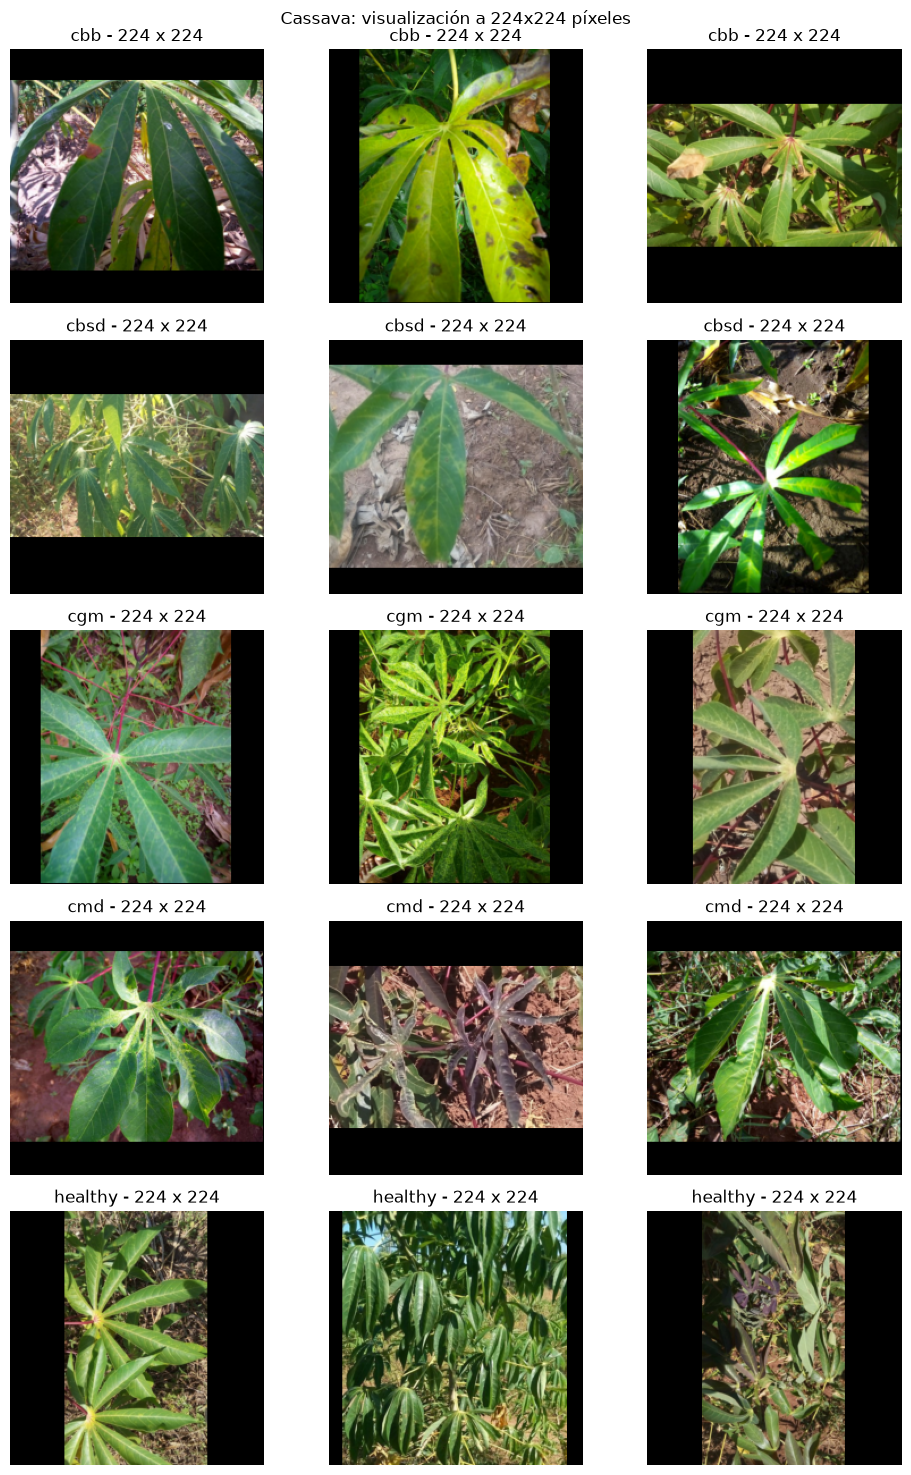

In [7]:
# PASO 4: Visualización de imágenes redimensionadas a 224x224
# Seleccionar 3 imágenes de cada clase del conjunto Train
muestras = {i: [] for i in range(len(clases))}

for registro in tfds.as_numpy(ds_train):
    etiqueta = int(registro["label"])

    if len(muestras[etiqueta]) < 3:
        muestras[etiqueta].append(registro["image"])

    # Detener cuando tengamos las 15 imágenes
    if all(len(lista) == 3 for lista in muestras.values()):
        break

# Mostrar las 15 imágenes con resolución de 224x224
fig, ejes = plt.subplots(5, 3, figsize=(10, 15))

for i, clase in enumerate(clases):
    for j, imagen in enumerate(muestras[i]):
        # Redimensionar conservando la proporción original
        imagen_224 = tf.image.resize_with_pad(
            imagen, 224, 224, antialias=True
        )
        # Visualizar la imagen con su etiqueta
        ejes[i, j].imshow(tf.cast(imagen_224, tf.uint8))
        ejes[i, j].set_title(f"{clase} - 224 x 224")
        ejes[i, j].axis("off")

plt.suptitle("Cassava: visualización a 224x224 píxeles")
plt.tight_layout()
plt.show()

In [8]:
# PASO 5: Preparación de datos para el entrenamiento
# Definir parámetros generales
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Función para redimensionar cada imagen y conservar su etiqueta
def preparar_imagen(registro):
    imagen = tf.image.resize_with_pad(
        registro["image"],
        IMG_SIZE[0],
        IMG_SIZE[1],
        antialias=True,)
    # Mantener los píxeles float32 en el rango común de 0 a 255.
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]
# Función para organizar los datos en lotes
def preparar_dataset(dataset, entrenamiento=False):

    # Mezclar únicamente las imágenes de entrenamiento
    if entrenamiento:
        dataset = dataset.shuffle(1000, seed=42)
    # Redimensionar las imágenes
    dataset = dataset.map(
        preparar_imagen, num_parallel_calls=AUTOTUNE
    )
    # Agrupar las imágenes y optimizar su lectura
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset
# Preparar Train, Validation y Test
train_preparado = preparar_dataset(ds_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val)
test_preparado = preparar_dataset(ds_test)

print("Datos preparados correctamente.")

# Comprobar las dimensiones de un lote
for imagenes, etiquetas in train_preparado.take(1):
    print("Dimensiones del lote:", imagenes.shape)
    print("Dimensiones de etiquetas:", etiquetas.shape)
    print("Tipo de dato:", imagenes.dtype)

Datos preparados correctamente.
Dimensiones del lote: (32, 224, 224, 3)
Dimensiones de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>


Clase        Fotos    Mediana        P90    Más de 50%
cbb            466      20.0%      24.9%          0.2%
cbsd          1443      24.9%      43.7%          0.0%
cgm            773      24.9%      43.7%          0.8%
cmd           2658      24.9%      43.7%          0.5%
healthy        316      20.0%      43.7%          0.6%


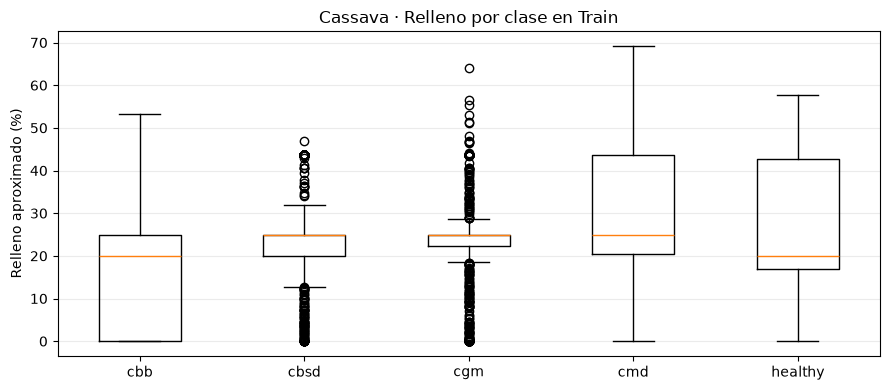

In [8]:
# PASO 6: Medir cuánto relleno necesita cada clase de Cassava
from collections import defaultdict

relleno_por_clase = defaultdict(list)

# Buscamos fotos casi cuadradas, moderadamente rectangulares y alargadas.
# El valor representa lado corto / lado largo.
proporciones_objetivo = [1.00, 0.75, 0.40]
muestras_comparacion = {}

for registro in tfds.as_numpy(ds_train):
    imagen = registro["image"]
    etiqueta = int(registro["label"])
    alto, ancho = imagen.shape[:2]

    proporcion = min(alto, ancho) / max(alto, ancho)
    porcentaje_relleno = 100 * (1 - proporcion)
    relleno_por_clase[etiqueta].append(porcentaje_relleno)

    # Guardar, para cada clase, la foto más cercana a cada proporción.
    for objetivo in proporciones_objetivo:
        clave = (etiqueta, objetivo)
        distancia = abs(proporcion - objetivo)
        anterior = muestras_comparacion.get(clave)

        if anterior is None or distancia < anterior["distancia"]:
            muestras_comparacion[clave] = {
                "distancia": distancia,
                "imagen": imagen,
                "relleno": porcentaje_relleno,
            }

print(f"{'Clase':<10} {'Fotos':>7} {'Mediana':>10} {'P90':>10} {'Más de 50%':>13}")

for etiqueta, nombre in enumerate(clases):
    valores = np.array(relleno_por_clase[etiqueta])

    print(
        f"{nombre:<10} {len(valores):>7} "
        f"{np.median(valores):>9.1f}% "
        f"{np.percentile(valores, 90):>9.1f}% "
        f"{np.mean(valores > 50) * 100:>12.1f}%"
    )

plt.figure(figsize=(9, 4))
plt.boxplot([relleno_por_clase[i] for i in range(len(clases))])
plt.xticks(range(1, len(clases) + 1), clases)
plt.ylabel("Relleno aproximado (%)")
plt.title("Cassava · Relleno por clase en Train")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

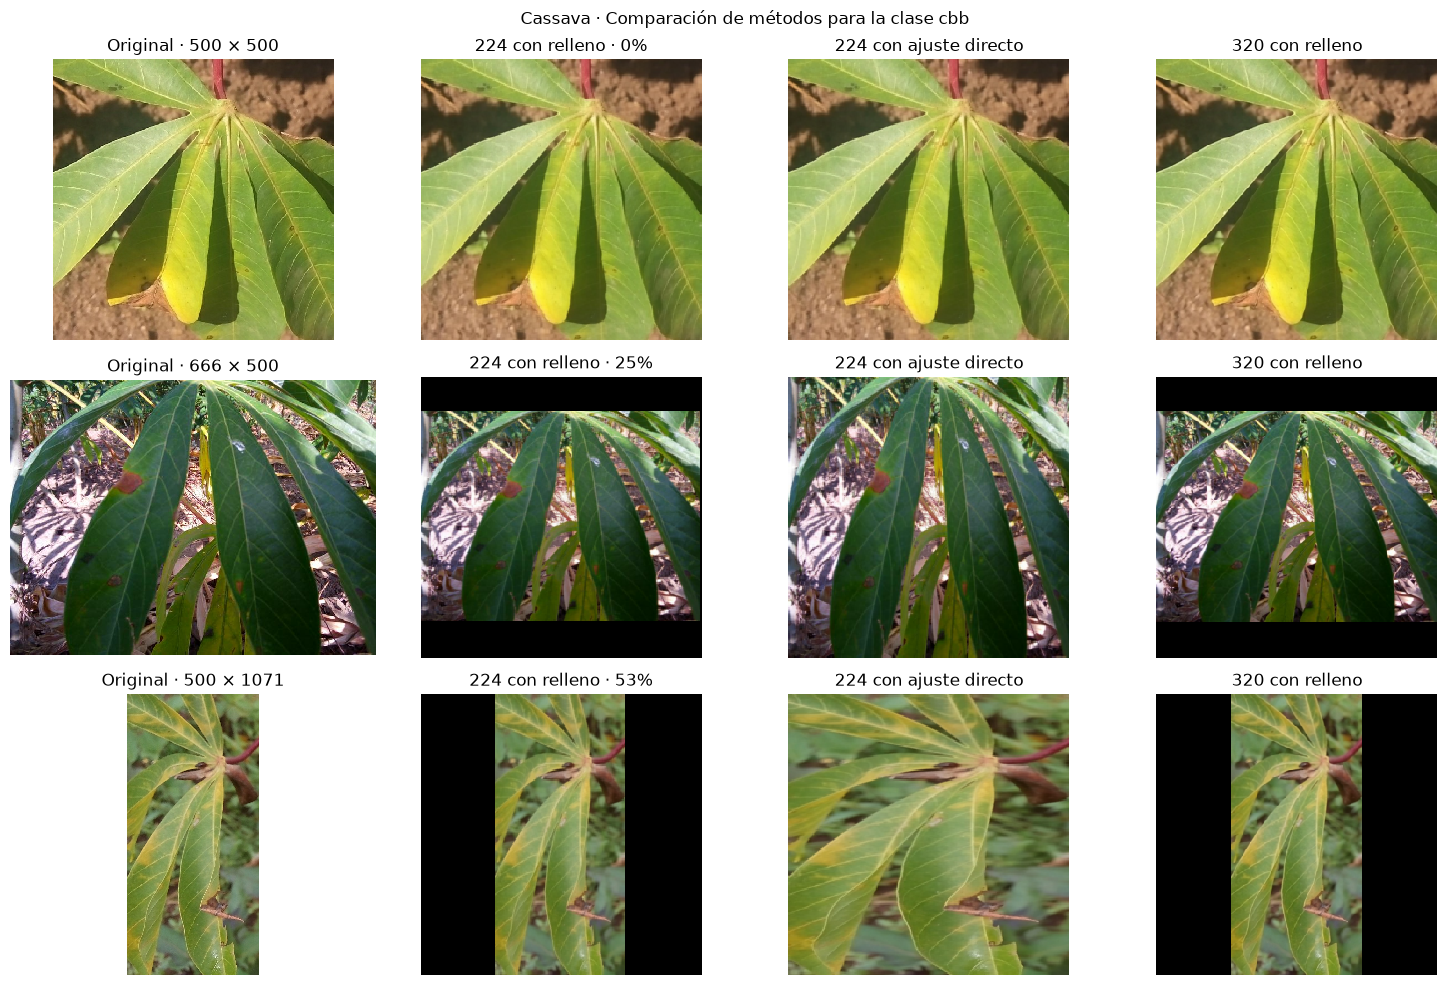

In [9]:
# PASO 7: Comparar el redimensionamiento sobre las mismas fotos
clase_a_revisar = "cbb"
etiqueta = list(clases).index(clase_a_revisar)

fig, ejes = plt.subplots(3, 4, figsize=(15, 10))

for fila, objetivo in enumerate(proporciones_objetivo):
    muestra = muestras_comparacion[(etiqueta, objetivo)]
    original = muestra["imagen"]
    alto, ancho = original.shape[:2]

    con_relleno_224 = tf.image.resize_with_pad(
        original, 224, 224, antialias=True
    )
    directo_224 = tf.image.resize(
        original, (224, 224), antialias=True
    )
    con_relleno_320 = tf.image.resize_with_pad(
        original, 320, 320, antialias=True
    )

    versiones = [
        (original, f"Original · {ancho} × {alto}"),
        (con_relleno_224, f"224 con relleno · {muestra['relleno']:.0f}%"),
        (directo_224, "224 con ajuste directo"),
        (con_relleno_320, "320 con relleno"),
    ]

    for eje, (imagen, titulo) in zip(ejes[fila], versiones):
        # Conversión solo para que Matplotlib muestre bien los colores.
        imagen_visible = np.clip(np.asarray(imagen), 0, 255).astype(np.uint8)
        eje.imshow(imagen_visible, interpolation="nearest")
        eje.set_title(titulo)
        eje.axis("off")

fig.suptitle(f"Cassava · Comparación de métodos para la clase {clase_a_revisar}")
plt.tight_layout()
plt.show()

In [10]:
print(f"Máximo real del lote: {tf.reduce_max(imagenes).numpy():.8f}")

Máximo real del lote: 255.00000000


In [11]:
# PASO 8: Verificar las entradas antes de entrenar la CNN propia
for nombre, dataset in [
    ("Train", train_preparado),
    ("Validation", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))

    tf.debugging.assert_shapes([
        (imagenes, ("lote", 224, 224, 3)),
        (etiquetas, ("lote",)),
    ])
    tf.debugging.assert_all_finite(imagenes, f"{nombre}: píxeles no finitos")
    tf.debugging.assert_greater_equal(imagenes, 0.0)
    tf.debugging.assert_less_equal(imagenes, 255.0)
    tf.debugging.assert_greater_equal(etiquetas, tf.cast(0, etiquetas.dtype))
    tf.debugging.assert_less(
        etiquetas, tf.cast(len(clases), etiquetas.dtype)
    )

    print(
        f"{nombre} | imágenes: {imagenes.shape} | "
        f"etiquetas: {etiquetas.shape} | "
        f"píxeles: {float(tf.reduce_min(imagenes)):.1f} a "
        f"{float(tf.reduce_max(imagenes)):.1f}"
    )
print("Los lotes de Train y Validation pasaron la verificación.")

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Los lotes de Train y Validation pasaron la verificación.


## Construcción de DenseNet121 para Cassava

Usamos DenseNet121 con pesos preentrenados en ImageNet. En esta primera
configuración congelamos la base del modelo y agregamos una capa de salida
con cinco neuronas, una por cada clase de Cassava.

El modelo recibe imágenes RGB de 224 × 224 con valores de 0 a 255.
La normalización específica de DenseNet se aplica dentro del modelo,
por lo que podemos reutilizar los lotes de la preparación de Cassava.

In [33]:
# Construir y configurar DenseNet121 para Cassava
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(42)

# Cargar la base preentrenada sin su clasificación original de ImageNet.
base_densenet = keras.applications.DenseNet121(
    include_top=False,
    weights="imagenet",
    input_shape=(*IMG_SIZE, 3),
    pooling="avg",
)

# Durante la primera prueba solo se entrenará la nueva capa de salida.
base_densenet.trainable = False

entrada = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")

# Convertir de 0–255 a 0–1 y aplicar la normalización de DenseNet.
x = layers.Rescaling(1.0 / 255.0, name="reescalado")(entrada)
x = layers.Normalization(
    axis=-1,
    mean=[0.485, 0.456, 0.406],
    variance=[0.229**2, 0.224**2, 0.225**2],
    name="normalizacion_imagenet",
)(x)

caracteristicas = base_densenet(x, training=False)
salida = layers.Dense(
    len(clases),
    activation="softmax",
    name="clasificacion_cassava",
)(caracteristicas)

modelo_densenet = keras.Model(
    inputs=entrada,
    outputs=salida,
    name="densenet121_cassava",
)

modelo_densenet.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

modelo_densenet.summary()

Model: "densenet121_cassava"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reescalado (Rescaling)          │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacion_imagenet          │ (None, 224, 224, 3)    │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 1024)           │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clasificacion_cassava (Dense)   │ (None, 5)              │         5,125 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,042,629 (26.87 MB)

 Trainable params: 5,125 (20.02 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [15]:
# Prueba corta de DenseNet121
modelo_densenet.fit(
    train_preparado.take(2),
    validation_data=val_preparado.take(1),
    epochs=1,
    verbose=1,
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 20s 6s/step - accuracy: 0.2812 - loss: 1.9469 - val_accuracy: 0.3125 - val_loss: 1.9548


In [16]:
# Primer entrenamiento de DenseNet121 para Cassava
from datetime import datetime
from pathlib import Path

carpeta_notebook = Path.cwd()
carpeta_cassava = (
    carpeta_notebook
    if carpeta_notebook.name == "cassava"
    else carpeta_notebook / "cassava"
)

if not (carpeta_cassava / "DenseNet121.ipynb").is_file():
    raise FileNotFoundError(
        "Abre la carpeta BeanCass AI en VS Code y ejecuta esta celda desde allí."
    )

nombre_corrida = datetime.now().strftime("corrida_%Y%m%d_%H%M%S")
carpeta_corrida = carpeta_cassava / "resultados" / "densenet121" / nombre_corrida
carpeta_corrida.mkdir(parents=True, exist_ok=False)

ruta_modelo = carpeta_corrida / "mejor_modelo.keras"
print("Los resultados se guardarán en", carpeta_corrida.resolve())

historial_densenet = modelo_densenet.fit(
    train_preparado,
    validation_data=val_preparado,
    epochs=5,
    shuffle=False,
    callbacks=[
        keras.callbacks.CSVLogger(str(carpeta_corrida / "historial.csv")),
        keras.callbacks.ModelCheckpoint(
            filepath=str(ruta_modelo),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=2,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

Los resultados se guardarán en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\corrida_20261115_171624
Epoch 1/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.6038 - loss: 1.0623 - val_accuracy: 0.6998 - val_loss: 0.8444
Epoch 2/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 188s 1s/step - accuracy: 0.7212 - loss: 0.7884 - val_accuracy: 0.7279 - val_loss: 0.7647
Epoch 3/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 189s 1s/step - accuracy: 0.7452 - loss: 0.7123 - val_accuracy: 0.7305 - val_loss: 0.7278
Epoch 4/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 190s 1s/step - accuracy: 0.7618 - loss: 0.6726 - val_accuracy: 0.7454 - val_loss: 0.6984
Epoch 5/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.7767 - loss: 0.6411 - val_accuracy: 0.7570 - val_loss: 0.6795


In [17]:
# Evaluar el mejor DenseNet121 en Validation
modelo_guardado = keras.models.load_model(str(ruta_modelo))
matriz = np.zeros((len(clases), len(clases)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_guardado(imagenes, training=False)
    predicciones = np.argmax(probabilidades.numpy(), axis=1)
    np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

aciertos = matriz.diagonal()
reales = matriz.sum(axis=1)
predichas = matriz.sum(axis=0)
f1_por_clase = 2 * aciertos / np.maximum(reales + predichas, 1)

print("Orden de clases:", list(clases))
print("Matriz de confusión (filas reales, columnas predichas):")
print(matriz)
print()

for i, clase in enumerate(clases):
    print(f"{clase}: {aciertos[i]} de {reales[i]} correctas")

print(f"\nF1 macro: {f1_por_clase.mean():.4f}")

Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 86  33   6  22   9]
 [ 29 344   9  81  19]
 [  6  30 115  95  12]
 [  9  36  19 811  12]
 [  3  17   2  10  74]]

cbb: 86 de 156 correctas
cbsd: 344 de 482 correctas
cgm: 115 de 258 correctas
cmd: 811 de 887 correctas
healthy: 74 de 106 correctas

F1 macro: 0.6754


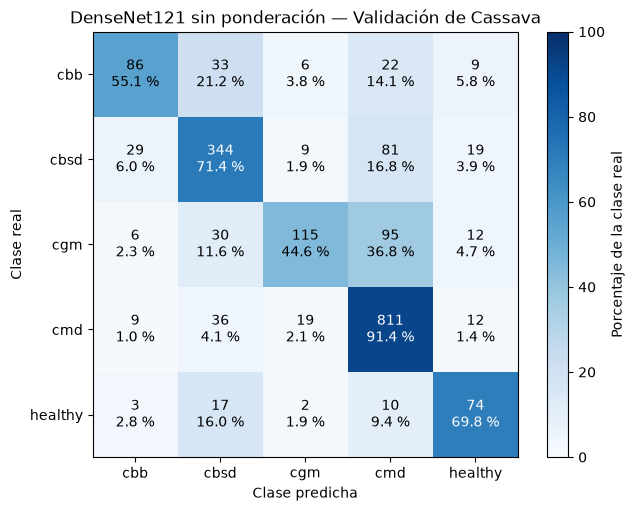

Aciertos en Validation: 1430 de 1889


In [9]:
# Ubicar la primera corrida desde la carpeta del proyecto o desde cassava.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_sin_ponderacion = (
    carpeta_cassava / "resultados" / "densenet121" / "corrida_20261115_171624"
)

# Cargar el modelo guardado y contar sus predicciones en Validation.
modelo = keras.models.load_model(
    str(carpeta_sin_ponderacion / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz = np.zeros((len(nombres), len(nombres)), dtype=int)

for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
    np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

# Dibujar los conteos y el porcentaje dentro de cada clase real.
porcentajes = 100 * matriz / matriz.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")

ax.set_xticks(range(len(nombres)), labels=nombres)
ax.set_yticks(range(len(nombres)), labels=nombres)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("DenseNet121 sin ponderación — Validación de Cassava")

for fila, columna in np.ndindex(matriz.shape):
    conteo = matriz[fila, columna]
    porcentaje = porcentajes[fila, columna]
    ax.text(
        columna, fila, f"{conteo}\n{porcentaje:.1f} %",
        ha="center", va="center",
        color="white" if porcentaje >= 60 else "black",
    )

# Guardar la figura junto al modelo y mostrarla en el notebook.
ruta_figura = carpeta_sin_ponderacion / "matriz_confusion_validation.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()

print(f"Aciertos en Validation: {matriz.trace()} de {matriz.sum()}")

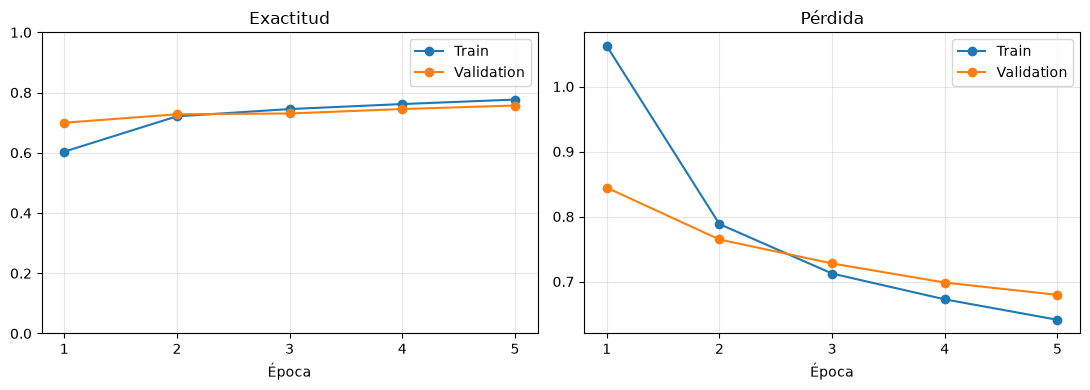

In [22]:
# Leer las métricas que se guardaron al terminar cada época.
with (carpeta_corrida / "historial.csv").open(
    encoding="utf-8", newline=""
) as archivo:
    registros = list(csv.DictReader(archivo))

# El CSV numera las épocas desde 0. En la gráfica las mostramos desde 1.
epocas = [int(fila["epoch"]) + 1 for fila in registros]

# Colocar exactitud y pérdida lado a lado para revisar las dos tendencias.
fig, (ax_accuracy, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))

for eje, metrica, titulo in [
    (ax_accuracy, "accuracy", "Exactitud"),
    (ax_loss, "loss", "Pérdida"),
]:
    # Comparar la misma métrica en Train y Validation.
    valores_train = [float(fila[metrica]) for fila in registros]
    valores_val = [float(fila[f"val_{metrica}"]) for fila in registros]
    eje.plot(epocas, valores_train, marker="o", label="Train")
    eje.plot(epocas, valores_val, marker="o", label="Validation")

    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_xticks(epocas)
    eje.grid(alpha=0.3)
    eje.legend()

# Mostrar la exactitud en su escala completa, de 0 a 1.
ax_accuracy.set_ylim(0, 1)

# Guardar la figura junto al historial para usarla en el informe.
fig.tight_layout()
fig.savefig(carpeta_corrida / "curvas_entrenamiento.png", dpi=150)
plt.show()

In [24]:
# Segunda corrida de DenseNet121 con ponderación de clases.
from datetime import datetime
from pathlib import Path

# Usar solo los conteos de Train para calcular los pesos.
conteos_train = {
    "cbb": 466,
    "cbsd": 1443,
    "cgm": 773,
    "cmd": 2658,
    "healthy": 316,
}

# Una clase con menos imágenes recibe más peso en la pérdida.
total_train = sum(conteos_train.values())
pesos_clase = {
    indice: total_train / (len(clases) * conteos_train[nombre])
    for indice, nombre in enumerate(clases)
}

for indice, nombre in enumerate(clases):
    print(f"{nombre}: {conteos_train[nombre]} fotos, peso {pesos_clase[indice]:.2f}")

# Crear una carpeta exclusiva para guardar esta corrida.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual
    if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "DenseNet121.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

nombre_corrida = datetime.now().strftime("ponderada_%Y%m%d_%H%M%S")
carpeta_corrida = carpeta_cassava / "resultados" / "densenet121" / nombre_corrida
carpeta_corrida.mkdir(parents=True, exist_ok=False)
ruta_modelo = carpeta_corrida / "mejor_modelo.keras"

print("Los resultados se guardarán en", carpeta_corrida.resolve())

# Entrenar con ponderación y evaluar con la misma partición de Validation.
historial_densenet = modelo_densenet.fit(
    train_preparado,
    validation_data=val_preparado,
    class_weight=pesos_clase,
    epochs=5,
    shuffle=False,
    callbacks=[
        # Guardar las métricas al final de cada época.
        keras.callbacks.CSVLogger(str(carpeta_corrida / "historial.csv")),
        # Guardar el modelo con la menor pérdida en Validation.
        keras.callbacks.ModelCheckpoint(
            filepath=str(ruta_modelo),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        # Detener la corrida si Validation deja de mejorar durante dos épocas.
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=2,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

cbb: 466 fotos, peso 2.43
cbsd: 1443 fotos, peso 0.78
cgm: 773 fotos, peso 1.46
cmd: 2658 fotos, peso 0.43
healthy: 316 fotos, peso 3.58
Los resultados se guardarán en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_20261115_181802
Epoch 1/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 195s 1s/step - accuracy: 0.4857 - loss: 1.2607 - val_accuracy: 0.6633 - val_loss: 0.9707
Epoch 2/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 163s 921ms/step - accuracy: 0.6600 - loss: 0.9452 - val_accuracy: 0.6877 - val_loss: 0.8699
Epoch 3/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 168s 948ms/step - accuracy: 0.6994 - loss: 0.8527 - val_accuracy: 0.7147 - val_loss: 0.8295
Epoch 4/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 167s 943ms/step - accuracy: 0.7130 - loss: 0.8048 - val_accuracy: 0.7268 - val_loss: 0.7712
Epoch 5/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 166s 933ms/step - accuracy: 0.7277 - loss: 0.7626 - val_accuracy: 0.6707 - val_loss: 0.8861


In [25]:
# Cargar el modelo guardado en la época con menor pérdida de validación.
modelo_ponderado = keras.models.load_model(str(ruta_modelo))

# Contar las predicciones. Las filas son las clases reales
# y las columnas son las clases predichas.
matriz_ponderada = np.zeros((len(clases), len(clases)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_ponderado(imagenes, training=False)
    predicciones = np.argmax(probabilidades.numpy(), axis=1)
    np.add.at(matriz_ponderada, (etiquetas.numpy(), predicciones), 1)

# Calcular el rendimiento por clase a partir de la matriz.
aciertos = matriz_ponderada.diagonal()
reales = matriz_ponderada.sum(axis=1)
predichas = matriz_ponderada.sum(axis=0)

precision = aciertos / np.maximum(predichas, 1)
recall = aciertos / np.maximum(reales, 1)
f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

print("Orden de clases:", list(clases))
print("Matriz de confusión:")
print(matriz_ponderada)

print("\nClase    Aciertos    Precisión   Recall      F1")
for i, clase in enumerate(clases):
    print(
        f"{clase:<8} {aciertos[i]:>3}/{reales[i]:<5}"
        f" {precision[i]:>8.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}"
    )

print(f"\nExactitud en Validation: {aciertos.sum() / reales.sum():.2%}")
print(f"F1 macro: {f1.mean():.4f}")

indice_cgm = list(clases).index("cgm")
indice_cmd = list(clases).index("cmd")
print(f"Imágenes cgm confundidas con cmd: {matriz_ponderada[indice_cgm, indice_cmd]}")

Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión:
[[ 93  21   9  16  17]
 [ 57 264  18  86  57]
 [  8  14 143  71  22]
 [ 11  24  38 779  35]
 [  2   1   2   7  94]]

Clase    Aciertos    Precisión   Recall      F1
cbb       93/156     54.39%    59.62%   0.5688
cbsd     264/482     81.48%    54.77%   0.6551
cgm      143/258     68.10%    55.43%   0.6111
cmd      779/887     81.23%    87.82%   0.8440
healthy   94/106     41.78%    88.68%   0.5680

Exactitud en Validation: 72.68%
F1 macro: 0.6494
Imágenes cgm confundidas con cmd: 71


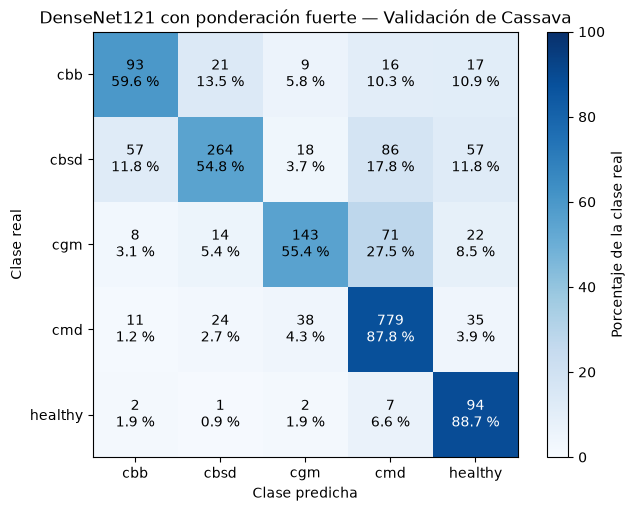

Aciertos en Validation: 1373 de 1889
Figura guardada en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_20261115_181802\matriz_confusion_validation.png


In [10]:
# Ubicar la segunda corrida desde la raíz del proyecto o desde cassava.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_ponderada = (
    carpeta_cassava / "resultados" / "densenet121" / "ponderada_20261115_181802"
)

# Cargar el modelo guardado y contar sus predicciones en Validation.
modelo_ponderado = keras.models.load_model(
    str(carpeta_ponderada / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz_ponderada = np.zeros((len(nombres), len(nombres)), dtype=int)

for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(
        modelo_ponderado(imagenes, training=False).numpy(), axis=1
    )
    np.add.at(matriz_ponderada, (etiquetas.numpy(), predicciones), 1)

# Dibujar el conteo y el porcentaje dentro de cada clase real.
porcentajes = 100 * matriz_ponderada / matriz_ponderada.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")

ax.set_xticks(range(len(nombres)), labels=nombres)
ax.set_yticks(range(len(nombres)), labels=nombres)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("DenseNet121 con ponderación fuerte — Validación de Cassava")

for fila, columna in np.ndindex(matriz_ponderada.shape):
    conteo = matriz_ponderada[fila, columna]
    porcentaje = porcentajes[fila, columna]
    ax.text(
        columna, fila, f"{conteo}\n{porcentaje:.1f} %",
        ha="center", va="center",
        color="white" if porcentaje >= 60 else "black",
    )

# Guardar la figura en la carpeta de la segunda corrida.
ruta_figura = carpeta_ponderada / "matriz_confusion_validation.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()

print(f"Aciertos en Validation: {matriz_ponderada.trace()} de {matriz_ponderada.sum()}")
print("Figura guardada en", ruta_figura.resolve())

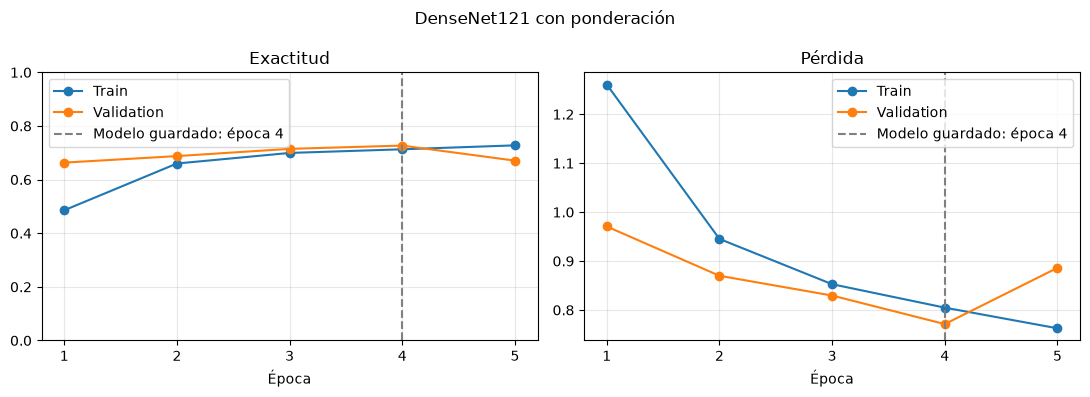

In [26]:
# Leer el historial de la corrida ponderada.
with (carpeta_corrida / "historial.csv").open(
    encoding="utf-8", newline=""
) as archivo:
    registros = list(csv.DictReader(archivo))

epocas = [int(fila["epoch"]) + 1 for fila in registros]
mejor_fila = min(registros, key=lambda fila: float(fila["val_loss"]))
mejor_epoca = int(mejor_fila["epoch"]) + 1

# Comparar Train y Validation e indicar la época elegida.
fig, (ax_accuracy, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("DenseNet121 con ponderación")

for eje, metrica, titulo in [
    (ax_accuracy, "accuracy", "Exactitud"),
    (ax_loss, "loss", "Pérdida"),
]:
    train = [float(fila[metrica]) for fila in registros]
    validation = [float(fila[f"val_{metrica}"]) for fila in registros]

    eje.plot(epocas, train, marker="o", label="Train")
    eje.plot(epocas, validation, marker="o", label="Validation")
    eje.axvline(
        mejor_epoca, color="gray", linestyle="--",
        label=f"Modelo guardado: época {mejor_epoca}",
    )
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_xticks(epocas)
    eje.grid(alpha=0.3)
    eje.legend()

ax_accuracy.set_ylim(0, 1)

# Guardar la imagen en la carpeta de esta corrida.
fig.tight_layout()
fig.savefig(carpeta_corrida / "curvas_entrenamiento.png", dpi=150)
plt.show()

In [29]:
# Tercera corrida de DenseNet121 con ponderación moderada de clases.
from datetime import datetime
from pathlib import Path

# Calcular los pesos originales usando solo las imágenes de Train.
conteos_train = {
    "cbb": 466,
    "cbsd": 1443,
    "cgm": 773,
    "cmd": 2658,
    "healthy": 316,
}

total_train = sum(conteos_train.values())
pesos_originales = {
    indice: total_train / (len(clases) * conteos_train[nombre])
    for indice, nombre in enumerate(clases)
}

# Acercar cada peso a 1 para moderar el efecto de la ponderación.
pesos_clase = {
    indice: (1.0 + peso) / 2.0
    for indice, peso in pesos_originales.items()
}

for indice, nombre in enumerate(clases):
    print(f"{nombre}: {conteos_train[nombre]} fotos, peso {pesos_clase[indice]:.2f}")

# Crear una carpeta propia para el historial y el modelo de esta corrida.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual
    if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "DenseNet121.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

nombre_corrida = datetime.now().strftime("ponderada_moderada_%Y%m%d_%H%M%S")
carpeta_corrida = carpeta_cassava / "resultados" / "densenet121" / nombre_corrida
carpeta_corrida.mkdir(parents=True, exist_ok=False)
ruta_modelo = carpeta_corrida / "mejor_modelo.keras"

print("Los resultados se guardarán en", carpeta_corrida.resolve())

# Entrenar con pesos moderados y evaluar con la misma partición de Validation.
historial_densenet = modelo_densenet.fit(
    train_preparado,
    validation_data=val_preparado,
    class_weight=pesos_clase,
    epochs=5,
    shuffle=False,
    callbacks=[
        # Registrar las métricas al final de cada época.
        keras.callbacks.CSVLogger(str(carpeta_corrida / "historial.csv")),
        # Guardar el modelo de la época con menor pérdida de validación.
        keras.callbacks.ModelCheckpoint(
            filepath=str(ruta_modelo),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        # Detener el entrenamiento tras dos épocas sin mejora en val_loss.
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=2,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

cbb: 466 fotos, peso 1.71
cbsd: 1443 fotos, peso 0.89
cgm: 773 fotos, peso 1.23
cmd: 2658 fotos, peso 0.71
healthy: 316 fotos, peso 2.29
Los resultados se guardarán en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_moderada_20261115_201931
Epoch 1/5


177/177 ━━━━━━━━━━━━━━━━━━━━ 214s 1s/step - accuracy: 0.5866 - loss: 1.2096 - val_accuracy: 0.7020 - val_loss: 0.8838
Epoch 2/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 185s 1s/step - accuracy: 0.7093 - loss: 0.9011 - val_accuracy: 0.7369 - val_loss: 0.7607
Epoch 3/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.7412 - loss: 0.8128 - val_accuracy: 0.7501 - val_loss: 0.7183
Epoch 4/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 189s 1s/step - accuracy: 0.7595 - loss: 0.7625 - val_accuracy: 0.7501 - val_loss: 0.7080
Epoch 5/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 185s 1s/step - accuracy: 0.7670 - loss: 0.7295 - val_accuracy: 0.7597 - val_loss: 0.6832


In [30]:
# Comprobar que evaluamos la corrida con ponderación moderada.
if not carpeta_corrida.name.startswith("ponderada_moderada_"):
    raise ValueError("Selecciona la carpeta de la corrida moderada.")

ruta_moderada = carpeta_corrida / "mejor_modelo.keras"
modelo_moderado = keras.models.load_model(str(ruta_moderada))
nombres_clases = list(clases)

# Contar cada predicción en la fila real y la columna predicha.
matriz_moderada = np.zeros((len(clases), len(clases)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_moderado(imagenes, training=False)
    predicciones = np.argmax(probabilidades.numpy(), axis=1)
    np.add.at(matriz_moderada, (etiquetas.numpy(), predicciones), 1)

# Calcular precisión, recall y F1 para cada clase.
aciertos = matriz_moderada.diagonal()
reales = matriz_moderada.sum(axis=1)
predichas = matriz_moderada.sum(axis=0)

precision = aciertos / np.maximum(predichas, 1)
recall = aciertos / np.maximum(reales, 1)
f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

print("Orden de clases:", nombres_clases)
print("Matriz de confusión (filas reales, columnas predichas):")
print(matriz_moderada)

print("\nClase    Aciertos    Precisión   Recall      F1")
for i, clase in enumerate(nombres_clases):
    print(
        f"{clase:<8} {aciertos[i]:>3}/{reales[i]:<5}"
        f" {precision[i]:>8.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}"
    )

print(f"\nExactitud en Validation: {aciertos.sum() / reales.sum():.2%}")
print(f"F1 macro: {f1.mean():.4f}")

indice_cgm = nombres_clases.index("cgm")
indice_cmd = nombres_clases.index("cmd")
print(f"Imágenes cgm confundidas con cmd: {matriz_moderada[indice_cgm, indice_cmd]}")

Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 87  31   8  20  10]
 [ 32 330  13  83  24]
 [  7  26 137  77  11]
 [  9  37  24 803  14]
 [  3  13   2  10  78]]

Clase    Aciertos    Precisión   Recall      F1
cbb       87/156     63.04%    55.77%   0.5918
cbsd     330/482     75.51%    68.46%   0.7182
cgm      137/258     74.46%    53.10%   0.6199
cmd      803/887     80.87%    90.53%   0.8543
healthy   78/106     56.93%    73.58%   0.6420

Exactitud en Validation: 75.97%
F1 macro: 0.6852
Imágenes cgm confundidas con cmd: 77


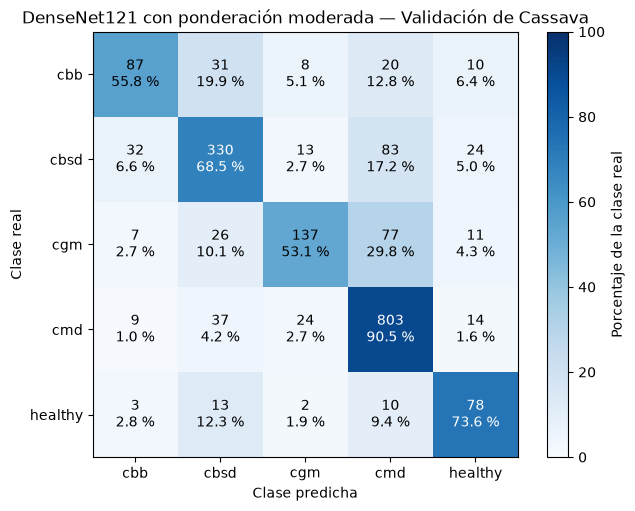

Aciertos en Validation: 1435 de 1889
Figura guardada en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_moderada_20261115_201931\matriz_confusion_validation.png


In [11]:
# Ubicar la carpeta de la corrida moderada completa.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_moderada = (
    carpeta_cassava / "resultados" / "densenet121"
    / "ponderada_moderada_20261115_201931"
)

# Cargar el modelo guardado y contar sus predicciones en Validation.
modelo_moderado = keras.models.load_model(
    str(carpeta_moderada / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz_moderada = np.zeros((len(nombres), len(nombres)), dtype=int)

for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(
        modelo_moderado(imagenes, training=False).numpy(), axis=1
    )
    np.add.at(matriz_moderada, (etiquetas.numpy(), predicciones), 1)

# Mostrar el conteo y el porcentaje dentro de cada clase real.
porcentajes = 100 * matriz_moderada / matriz_moderada.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")

ax.set_xticks(range(len(nombres)), labels=nombres)
ax.set_yticks(range(len(nombres)), labels=nombres)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("DenseNet121 con ponderación moderada — Validación de Cassava")

for fila, columna in np.ndindex(matriz_moderada.shape):
    conteo = matriz_moderada[fila, columna]
    porcentaje = porcentajes[fila, columna]
    ax.text(
        columna, fila, f"{conteo}\n{porcentaje:.1f} %",
        ha="center", va="center",
        color="white" if porcentaje >= 60 else "black",
    )

# Guardar la figura en la carpeta de la tercera corrida.
ruta_figura = carpeta_moderada / "matriz_confusion_validation.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()

print(f"Aciertos en Validation: {matriz_moderada.trace()} de {matriz_moderada.sum()}")
print("Figura guardada en", ruta_figura.resolve())

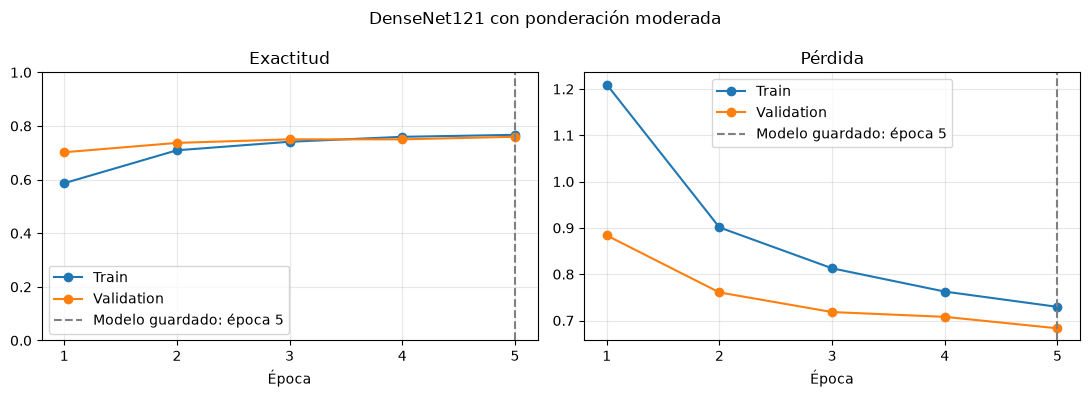

In [31]:
# Leer las métricas guardadas al final de cada época.
if not carpeta_corrida.name.startswith("ponderada_moderada_"):
    raise ValueError("Selecciona la carpeta de la corrida moderada.")

with (carpeta_corrida / "historial.csv").open(
    encoding="utf-8", newline=""
) as archivo:
    registros = list(csv.DictReader(archivo))

# Mostrar las épocas desde 1 y localizar la que guardó ModelCheckpoint.
epocas = [int(fila["epoch"]) + 1 for fila in registros]
mejor_fila = min(registros, key=lambda fila: float(fila["val_loss"]))
mejor_epoca = int(mejor_fila["epoch"]) + 1

# Comparar Train y Validation en las dos gráficas.
fig, (ax_accuracy, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("DenseNet121 con ponderación moderada")

for eje, metrica, titulo in [
    (ax_accuracy, "accuracy", "Exactitud"),
    (ax_loss, "loss", "Pérdida"),
]:
    train = [float(fila[metrica]) for fila in registros]
    validation = [float(fila[f"val_{metrica}"]) for fila in registros]

    eje.plot(epocas, train, marker="o", label="Train")
    eje.plot(epocas, validation, marker="o", label="Validation")
    eje.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {mejor_epoca}",
    )
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_xticks(epocas)
    eje.grid(alpha=0.3)
    eje.legend()

ax_accuracy.set_ylim(0, 1)

# Guardar la figura junto al historial de esta corrida.
fig.tight_layout()
fig.savefig(carpeta_corrida / "curvas_entrenamiento.png", dpi=150)
plt.show()

In [34]:
# Cuarta corrida de DenseNet121 con pesos ajustados para las cinco clases.
from datetime import datetime
from pathlib import Path

# Asignar los pesos usando el orden de clases del dataset.
pesos_por_nombre = {
    "cbb": 1.35,
    "cbsd": 1.00,
    "cgm": 1.23,
    "cmd": 0.85,
    "healthy": 1.65,
}
pesos_clase = {
    indice: pesos_por_nombre[nombre]
    for indice, nombre in enumerate(clases)
}

for indice, nombre in enumerate(clases):
    print(f"{nombre}: peso {pesos_clase[indice]:.2f}")

# Crear una carpeta propia para el historial y el modelo de esta corrida.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual
    if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)

if not (carpeta_cassava / "DenseNet121.ipynb").is_file():
    raise FileNotFoundError("Abre la carpeta BeanCass AI en VS Code.")

nombre_corrida = datetime.now().strftime("ponderada_ajustada_%Y%m%d_%H%M%S")
carpeta_corrida = carpeta_cassava / "resultados" / "densenet121" / nombre_corrida
carpeta_corrida.mkdir(parents=True, exist_ok=False)
ruta_modelo = carpeta_corrida / "mejor_modelo.keras"

print("Los resultados se guardarán en", carpeta_corrida.resolve())

# Mantener los mismos datos, el mismo límite de épocas y el mismo
# criterio de guardado para comparar el efecto de los nuevos pesos.
historial_densenet = modelo_densenet.fit(
    train_preparado,
    validation_data=val_preparado,
    class_weight=pesos_clase,
    epochs=5,
    shuffle=False,
    callbacks=[
        # Registrar las métricas de cada época.
        keras.callbacks.CSVLogger(str(carpeta_corrida / "historial.csv")),
        # Guardar el modelo de la época con menor pérdida en Validation.
        keras.callbacks.ModelCheckpoint(
            filepath=str(ruta_modelo),
            monitor="val_loss",
            mode="min",
            save_best_only=True,
        ),
        # Detener el entrenamiento tras dos épocas sin mejora en val_loss.
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            mode="min",
            patience=2,
            restore_best_weights=True,
        ),
    ],
    verbose=1,
)

cbb: peso 1.35
cbsd: peso 1.00
cgm: peso 1.23
cmd: peso 0.85
healthy: peso 1.65
Los resultados se guardarán en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_ajustada_20261115_212508
Epoch 1/5


177/177 ━━━━━━━━━━━━━━━━━━━━ 231s 1s/step - accuracy: 0.5988 - loss: 1.1918 - val_accuracy: 0.6961 - val_loss: 0.8531
Epoch 2/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 214s 1s/step - accuracy: 0.7217 - loss: 0.8824 - val_accuracy: 0.7253 - val_loss: 0.7940
Epoch 3/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 210s 1s/step - accuracy: 0.7484 - loss: 0.7993 - val_accuracy: 0.7517 - val_loss: 0.7152
Epoch 4/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 211s 1s/step - accuracy: 0.7588 - loss: 0.7533 - val_accuracy: 0.7507 - val_loss: 0.6950
Epoch 5/5
177/177 ━━━━━━━━━━━━━━━━━━━━ 243s 1s/step - accuracy: 0.7737 - loss: 0.7174 - val_accuracy: 0.7623 - val_loss: 0.6793


In [35]:
# Verificar que estamos usando la carpeta de la cuarta corrida.
if not carpeta_corrida.name.startswith("ponderada_ajustada_"):
    raise ValueError("Selecciona la carpeta de la cuarta corrida.")

# Cargar el modelo guardado con la menor pérdida de validación.
ruta_ajustada = carpeta_corrida / "mejor_modelo.keras"
modelo_ajustado = keras.models.load_model(str(ruta_ajustada))
nombres_clases = list(clases)

# Cada fila representa la clase real y cada columna la clase predicha.
matriz_ajustada = np.zeros((len(nombres_clases), len(nombres_clases)), dtype=int)

for imagenes, etiquetas in val_preparado:
    probabilidades = modelo_ajustado(imagenes, training=False)
    predicciones = np.argmax(probabilidades.numpy(), axis=1)
    np.add.at(matriz_ajustada, (etiquetas.numpy(), predicciones), 1)

# La diagonal contiene los aciertos de cada clase.
aciertos = matriz_ajustada.diagonal()
reales = matriz_ajustada.sum(axis=1)
predichas = matriz_ajustada.sum(axis=0)

precision = aciertos / np.maximum(predichas, 1)
recall = aciertos / np.maximum(reales, 1)
f1 = 2 * aciertos / np.maximum(reales + predichas, 1)

print("Orden de clases:", nombres_clases)
print("Matriz de confusión (filas reales, columnas predichas):")
print(matriz_ajustada)

print("\nClase    Aciertos    Precisión   Recall      F1")
for i, nombre in enumerate(nombres_clases):
    print(
        f"{nombre:<8} {aciertos[i]:>3}/{reales[i]:<5}"
        f" {precision[i]:>8.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}"
    )

print(f"\nExactitud en Validation: {aciertos.sum() / reales.sum():.2%}")
print(f"F1 macro: {f1.mean():.4f}")

# Mostrar las confusiones que motivaron la cuarta prueba.
indice_cmd = nombres_clases.index("cmd")
indice_healthy = nombres_clases.index("healthy")

for nombre in ("cgm", "healthy"):
    indice_real = nombres_clases.index(nombre)
    print(f"{nombre} → cmd: {matriz_ajustada[indice_real, indice_cmd]}")

print(
    "Hojas enfermas predichas como sanas:",
    predichas[indice_healthy] - aciertos[indice_healthy],
)

Orden de clases: ['cbb', 'cbsd', 'cgm', 'cmd', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[ 73  49  11  16   7]
 [ 14 397  14  50   7]
 [  3  36 148  65   6]
 [  7  68  52 754   6]
 [  3  23   2  10  68]]

Clase    Aciertos    Precisión   Recall      F1
cbb       73/156     73.00%    46.79%   0.5703
cbsd     397/482     69.28%    82.37%   0.7526
cgm      148/258     65.20%    57.36%   0.6103
cmd      754/887     84.25%    85.01%   0.8462
healthy   68/106     72.34%    64.15%   0.6800

Exactitud en Validation: 76.23%
F1 macro: 0.6919
cgm → cmd: 65
healthy → cmd: 10
Hojas enfermas predichas como sanas: 26


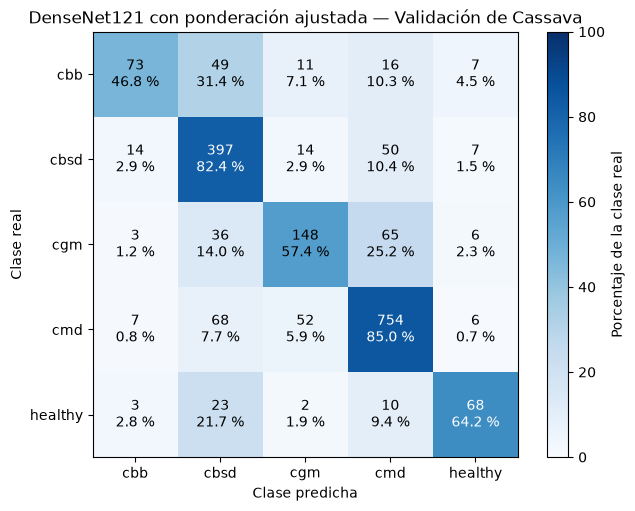

Aciertos en Validation: 1440 de 1889
Figura guardada en C:\Users\Asus\Documents\1 Universidad\Daniela\1 Semestres Software\7 Semestre\IA\BeanCass AI\cassava\resultados\densenet121\ponderada_ajustada_20261115_212508\matriz_confusion_validation.png


In [12]:
# Ubicar la carpeta de la cuarta corrida completa.
carpeta_actual = Path.cwd()
carpeta_cassava = (
    carpeta_actual if carpeta_actual.name == "cassava"
    else carpeta_actual / "cassava"
)
carpeta_ajustada = (
    carpeta_cassava / "resultados" / "densenet121"
    / "ponderada_ajustada_20261115_212508"
)

# Cargar el modelo guardado y contar sus predicciones en Validation.
modelo_ajustado = keras.models.load_model(
    str(carpeta_ajustada / "mejor_modelo.keras"), compile=False
)
nombres = list(clases)
matriz_ajustada = np.zeros((len(nombres), len(nombres)), dtype=int)

for imagenes, etiquetas in val_preparado:
    predicciones = np.argmax(
        modelo_ajustado(imagenes, training=False).numpy(), axis=1
    )
    np.add.at(matriz_ajustada, (etiquetas.numpy(), predicciones), 1)

# Mostrar el conteo y el porcentaje dentro de cada clase real.
porcentajes = 100 * matriz_ajustada / matriz_ajustada.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")

ax.set_xticks(range(len(nombres)), labels=nombres)
ax.set_yticks(range(len(nombres)), labels=nombres)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title("DenseNet121 con ponderación ajustada — Validación de Cassava")

for fila, columna in np.ndindex(matriz_ajustada.shape):
    conteo = matriz_ajustada[fila, columna]
    porcentaje = porcentajes[fila, columna]
    ax.text(
        columna, fila, f"{conteo}\n{porcentaje:.1f} %",
        ha="center", va="center",
        color="white" if porcentaje >= 60 else "black",
    )

# Guardar la figura junto al modelo de la cuarta corrida.
ruta_figura = carpeta_ajustada / "matriz_confusion_validation.png"
fig.savefig(ruta_figura, dpi=200)
plt.show()

print(f"Aciertos en Validation: {matriz_ajustada.trace()} de {matriz_ajustada.sum()}")
print("Figura guardada en", ruta_figura.resolve())

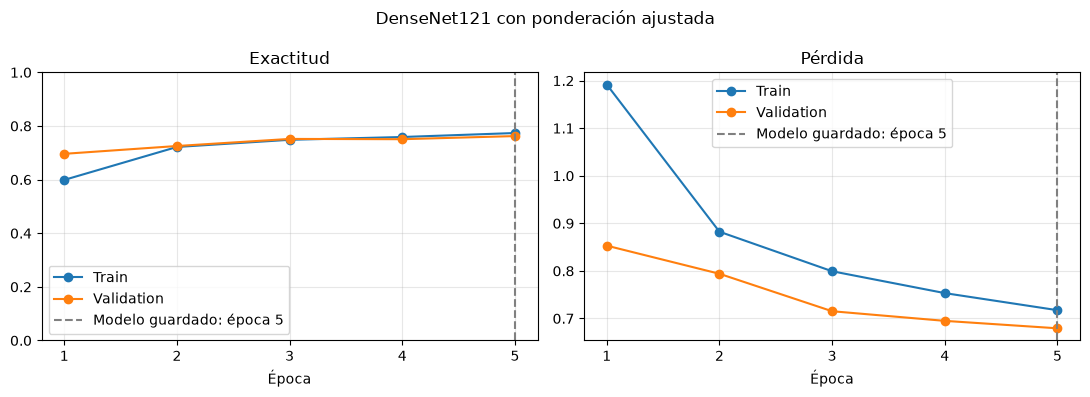

In [36]:
# Verificar la carpeta y leer las métricas de cada época.
if not carpeta_corrida.name.startswith("ponderada_ajustada_"):
    raise ValueError("Selecciona la carpeta de la cuarta corrida.")

with (carpeta_corrida / "historial.csv").open(
    encoding="utf-8", newline=""
) as archivo:
    registros = list(csv.DictReader(archivo))

# Mostrar las épocas desde 1 e identificar la de menor pérdida en Validation.
epocas = [int(fila["epoch"]) + 1 for fila in registros]
mejor_fila = min(registros, key=lambda fila: float(fila["val_loss"]))
mejor_epoca = int(mejor_fila["epoch"]) + 1

fig, (ax_accuracy, ax_loss) = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("DenseNet121 con ponderación ajustada")

# Comparar Train y Validation y marcar la época guardada.
for eje, metrica, titulo in [
    (ax_accuracy, "accuracy", "Exactitud"),
    (ax_loss, "loss", "Pérdida"),
]:
    train = [float(fila[metrica]) for fila in registros]
    validation = [float(fila[f"val_{metrica}"]) for fila in registros]

    eje.plot(epocas, train, marker="o", label="Train")
    eje.plot(epocas, validation, marker="o", label="Validation")
    eje.axvline(
        mejor_epoca,
        color="gray",
        linestyle="--",
        label=f"Modelo guardado: época {mejor_epoca}",
    )
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_xticks(epocas)
    eje.grid(alpha=0.3)
    eje.legend()

ax_accuracy.set_ylim(0, 1)

# Guardar la figura junto al historial de la cuarta corrida.
fig.tight_layout()
fig.savefig(carpeta_corrida / "curvas_entrenamiento.png", dpi=150)
plt.show()